<a href="https://colab.research.google.com/github/IvanovaKaryna/-/blob/main/%D0%9B%D0%A05_%D0%86%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_3_10_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import io
import zipfile

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

import warnings
warnings.filterwarnings('ignore')

plt.style.use('ggplot')

In [2]:
#Завантаження файлу
uploaded = files.upload()
filename = next(iter(uploaded))

#Читання CSV або ZIP
if filename.lower().endswith(".zip"):
    with zipfile.ZipFile(io.BytesIO(uploaded[filename])) as archive:
        csv_files = [f for f in archive.namelist() if f.lower().endswith(".csv")]

        if not csv_files:
            raise ValueError("У ZIP-архіві немає CSV-файлів.")

        df = pd.read_csv(archive.open(csv_files[0]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Файл успішно завантажено!")
print("Розмір датасету:", df.shape)

display(df.head())

print("\nІнформація про датасет:")
df.info()
print("\nСтатистичний опис:")
display(df.describe())
print("\nНазви стовпців:")
print(df.columns.tolist())


Saving archive (1).zip to archive (1) (2).zip
Файл успішно завантажено!
Розмір датасету: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303



Назви стовпців:
['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
print(df.columns.tolist())

['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
# Перевірте наявність пропущених значень
# Перегляньте інформацію про структуру датасет

if "DATE" in df.columns:
    df["DATE"] = pd.to_datetime(df["DATE"])
    df = df.sort_values("DATE")
    df = df.set_index("DATE")

df.index = pd.to_datetime(df.index)

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Інформація про датасет:")
df.info()

print("\nПропущені значення:")
print(df.isnull().sum())

display(df.head())




Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month         

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Графік температури

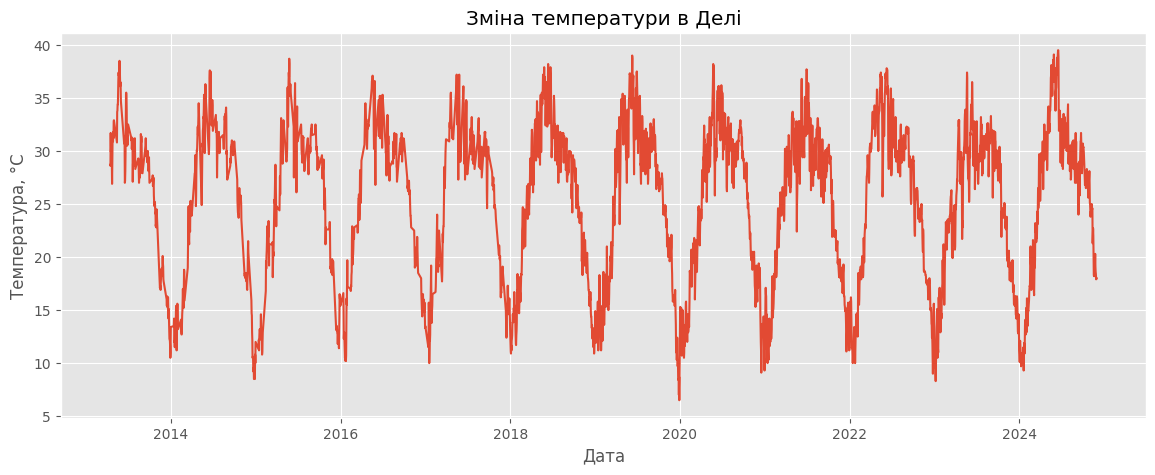

In [5]:
# Побудуйте графік зміни температури у часі

# Графік зміни температури у часі
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["temp"])
plt.title("Зміна температури в Делі")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.grid(True)
plt.show()


Ковзне середнє

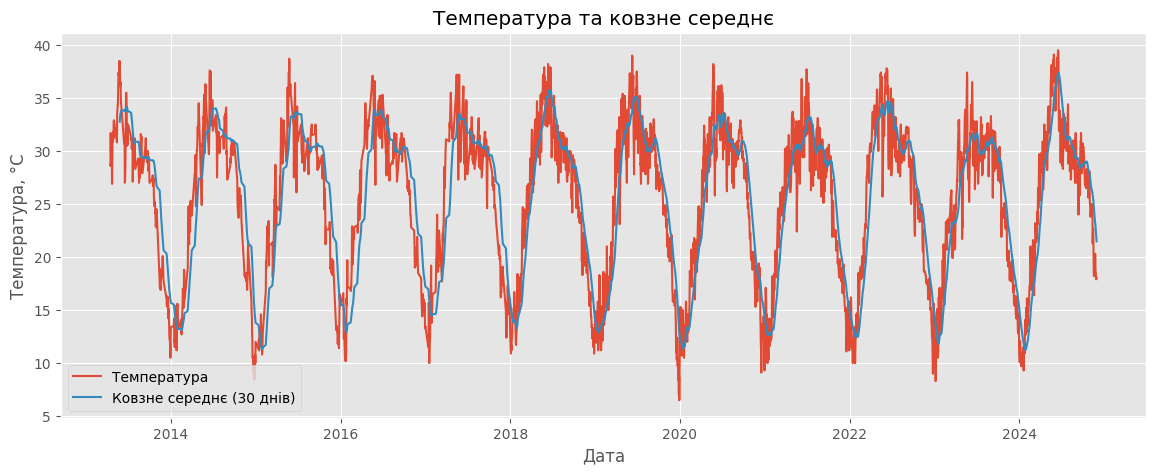

In [6]:
# Обчисліть та візуалізуйте ковзне середнє температури
df["temp_ma30"] = df["temp"].rolling(window=30).mean()

plt.figure(figsize=(14, 5))
plt.plot(df.index, df["temp"], label="Температура")
plt.plot(df.index, df["temp_ma30"], label="Ковзне середнє (30 днів)")
plt.title("Температура та ковзне середнє")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.legend()
plt.grid(True)
plt.show()


Розподіл температури

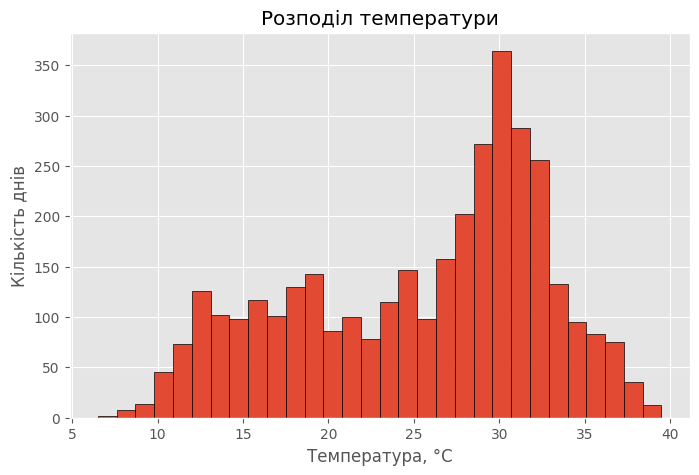

In [7]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8, 5))
plt.hist(df["temp"], bins=30, edgecolor="black")
plt.title("Розподіл температури")
plt.xlabel("Температура, °C")
plt.ylabel("Кількість днів")
plt.show()


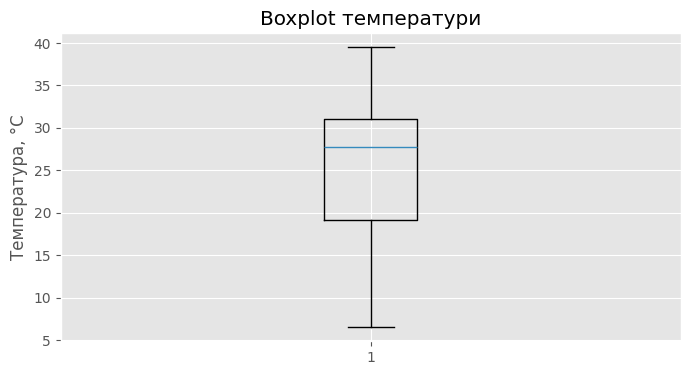

In [8]:
# Побудуйте boxplot температури для аналізу викидів

plt.figure(figsize=(8, 4))
plt.boxplot(df["temp"])
plt.title("Boxplot температури")
plt.ylabel("Температура, °C")
plt.grid(True)
plt.show()


Аналіз автокореляції
ACF

PACF

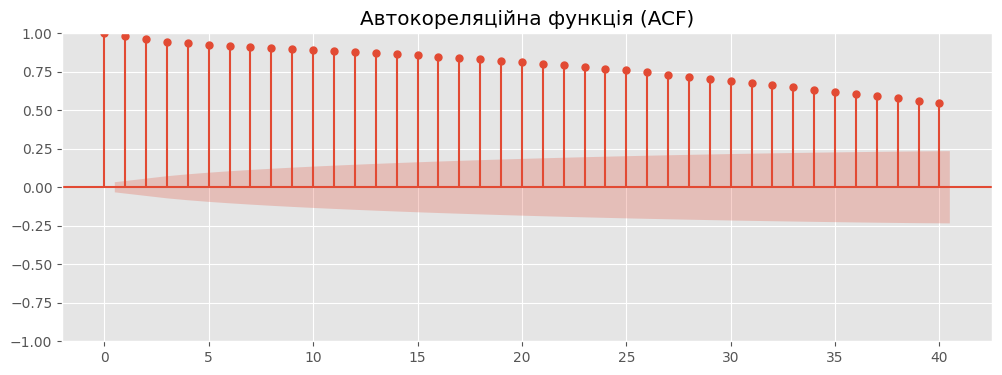

In [9]:
# Побудуйте графік автокореляційної функції (ACF)
plt.figure(figsize=(12, 4))
plot_acf(df["temp"], lags=40, ax=plt.gca())
plt.title("Автокореляційна функція (ACF)")
plt.show()



Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

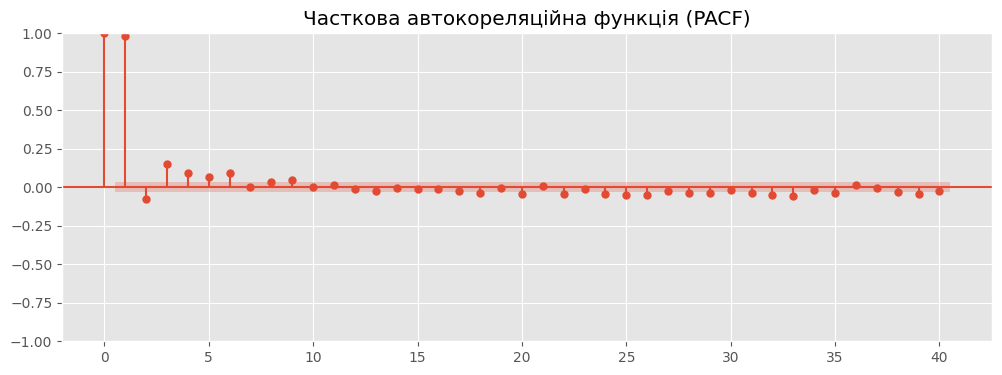

In [10]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plt.figure(figsize=(12, 4))
plot_pacf(df["temp"], lags=40, method="ywm", ax=plt.gca())
plt.title("Часткова автокореляційна функція (PACF)")
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [11]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
ts = df["temp"].astype(float)

# Розділення даних у часовому порядку: 80% / 20%
split_point = int(len(ts) * 0.8)

train = ts.iloc[:split_point]
test = ts.iloc[split_point:]

print("Кількість усіх записів:", len(ts))
print("Тренувальна вибірка:", len(train))
print("Тестова вибірка:", len(test))

print("\nПеріод тренувальних даних:")
print(train.index.min(), "-", train.index.max())

print("\nПеріод тестових даних:")
print(test.index.min(), "-", test.index.max())


Кількість усіх записів: 3557
Тренувальна вибірка: 2845
Тестова вибірка: 712

Період тренувальних даних:
2013-04-14 00:00:00 - 2022-12-19 00:00:00

Період тестових даних:
2022-12-20 00:00:00 - 2024-11-30 00:00:00


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [12]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
#Формування цільового часового ряду
ts = df["temp"].astype(float).copy()
#Перевірка та обробка дат
ts.index = pd.to_datetime(ts.index)
ts = ts.groupby(level=0).mean()
ts = ts.sort_index()
#Встановлення щоденної частоти
ts = ts.asfreq("D")
#Заповнення пропущених значень
ts = ts.interpolate(method="time")
#Розділення даних у часовому порядку
split_point = int(len(ts) * 0.8)

train = ts.iloc[:split_point]
test = ts.iloc[split_point:]

print("Усього записів:", len(ts))
print("Тренувальна вибірка:", len(train))
print("Тестова вибірка:", len(test))
print("Повторювані дати:", ts.index.duplicated().sum())
print("Пропущені значення:", ts.isna().sum())



Усього записів: 4249
Тренувальна вибірка: 3399
Тестова вибірка: 850
Повторювані дати: 0
Пропущені значення: 0


In [13]:
model_arima = ARIMA(train, order=(5, 1, 2))
arima_fit = model_arima.fit()
forecast_arima = arima_fit.forecast(steps=len(test))
forecast_arima.index = test.index

print("Прогноз ARIMA побудовано!")
display(forecast_arima.head())


Прогноз ARIMA побудовано!


,predicted_mean
DATE,
2022-08-04,30.456565
2022-08-05,30.261076
2022-08-06,30.145703
2022-08-07,30.057663
2022-08-08,30.046859


In [14]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -5406.262
Date:                Wed, 21 Oct 2026   AIC                          10828.523
Time:                        13:37:47   BIC                          10877.571
Sample:                    04-14-2013   HQIC                         10846.054
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2737      0.298      0.918      0.359      -0.311       0.858
ar.L2          0.1120      0.269      0.416      0.678      -0.416       0.640
ar.L3         -0.0937      0.073     -1.283      0.2

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

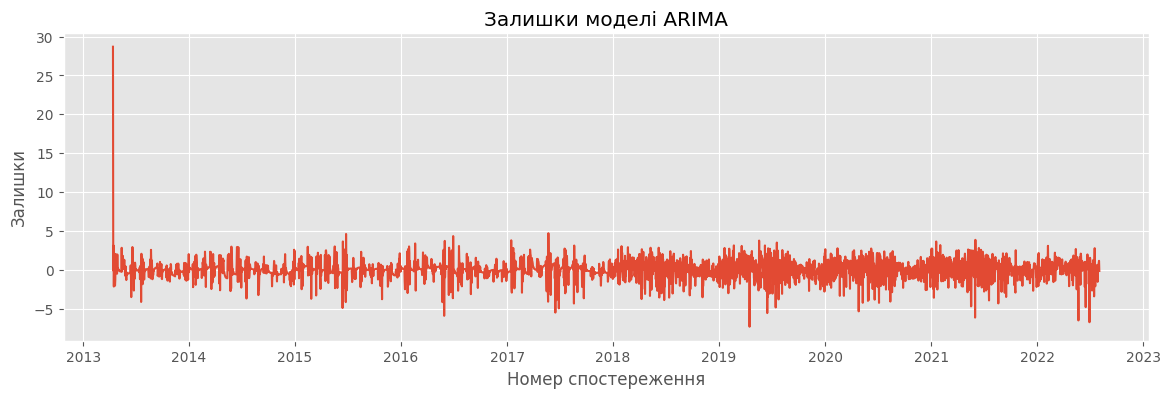

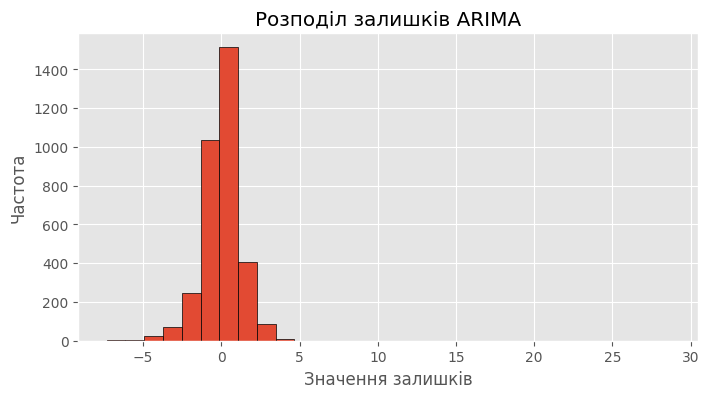

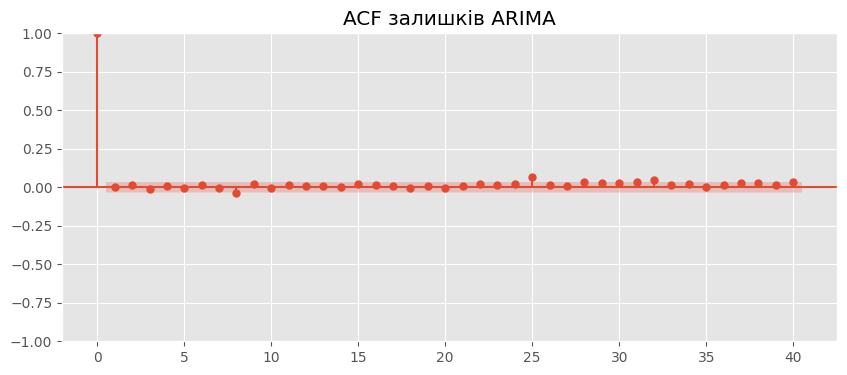

In [15]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки

# Аналіз залишків ARIMA-моделі
residuals = arima_fit.resid

#Графік залишків
plt.figure(figsize=(14, 4))
plt.plot(residuals)
plt.title("Залишки моделі ARIMA")
plt.xlabel("Номер спостереження")
plt.ylabel("Залишки")
plt.grid(True)
plt.show()

#Гістограма залишків
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=30, edgecolor="black")
plt.title("Розподіл залишків ARIMA")
plt.xlabel("Значення залишків")
plt.ylabel("Частота")
plt.show()

#Автокореляція залишків
plt.figure(figsize=(10, 4))
plot_acf(residuals, lags=40, ax=plt.gca())
plt.title("ACF залишків ARIMA")
plt.show()


In [16]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
#MAPE
def calculate_mape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

#ARIMA
mae_arima = mean_absolute_error(test, forecast_arima)
rmse_arima = np.sqrt(mean_squared_error(test, forecast_arima))
mape_arima = calculate_mape(test, forecast_arima)

print("Результати ARIMA:")
print("MAE:", round(mae_arima, 3))
print("RMSE:", round(rmse_arima, 3))
print("MAPE:", round(mape_arima, 3), "%")


Результати ARIMA:
MAE: 6.196
RMSE: 8.404
MAPE: 35.793 %


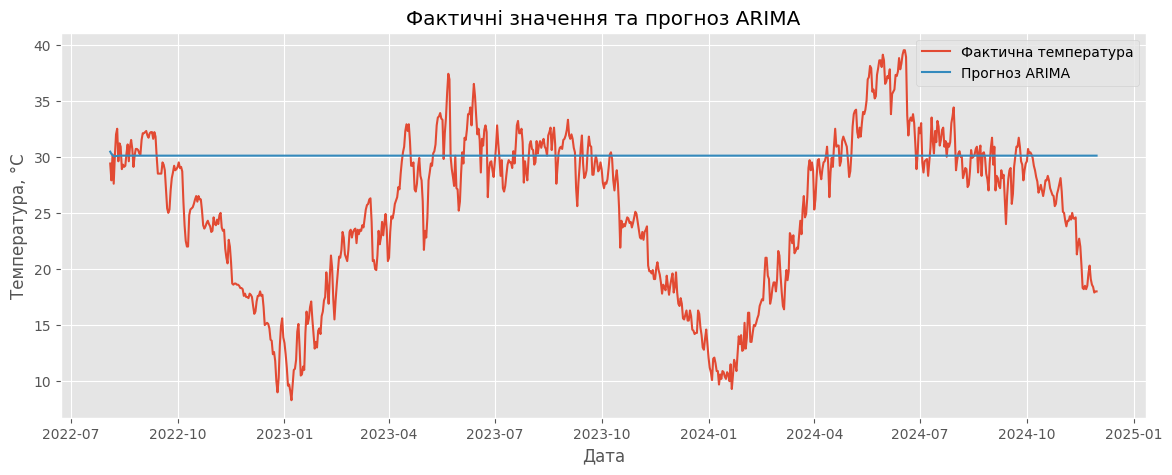

In [17]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактична температура")
plt.plot(forecast_arima.index, forecast_arima, label="Прогноз ARIMA")
plt.title("Фактичні значення та прогноз ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.legend()
plt.grid(True)
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [18]:
!pip install prophet


In [19]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_data = pd.DataFrame({
    "ds": ts.index,
    "y": ts.values
})

#Розділення даних у часовому порядку
prophet_train = prophet_data.iloc[:split_point].copy()
prophet_test = prophet_data.iloc[split_point:].copy()

print("Тренувальні дані:")
display(prophet_train.head())

print("Тестові дані:")
display(prophet_test.head())


Тренувальні дані:


,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


Тестові дані:


,ds,y
3399,2022-08-04,29.4
3400,2022-08-05,27.9
3401,2022-08-06,30.2
3402,2022-08-07,27.6
3403,2022-08-08,30.1


In [20]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

#Створення та навчання моделі Prophet
model_prophet = Prophet()
model_prophet.fit(prophet_train)

print("Модель Prophet навчена.")


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Модель Prophet навчена.


Прогноз

In [21]:
# Побудуйте прогноз Prophet для тестового періоду
future = prophet_test[["ds"]].copy()
forecast_prophet = model_prophet.predict(future)

#Фактичні та прогнозовані значення
y_true_prophet = prophet_test["y"].values
y_pred_prophet = forecast_prophet["yhat"].values

display(forecast_prophet[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())


,ds,yhat,yhat_lower,yhat_upper
0,2022-08-04,30.472997,27.975303,33.160037
1,2022-08-05,30.501332,27.849740,32.992140
2,2022-08-06,30.522214,28.110457,33.186082
3,2022-08-07,30.534157,27.924685,33.173312
4,2022-08-08,30.675759,28.148857,33.286826


In [22]:
# Обчисліть MAE, RMSE, MAPE для Prophet
mae_prophet = mean_absolute_error(y_true_prophet, y_pred_prophet)
rmse_prophet = np.sqrt(mean_squared_error(y_true_prophet, y_pred_prophet))
mape_prophet = calculate_mape(y_true_prophet, y_pred_prophet)

print("Результати Prophet:")
print("MAE:", round(mae_prophet, 3))
print("RMSE:", round(rmse_prophet, 3))
print("MAPE:", round(mape_prophet, 3), "%")


Результати Prophet:
MAE: 2.067
RMSE: 2.646
MAPE: 9.342 %


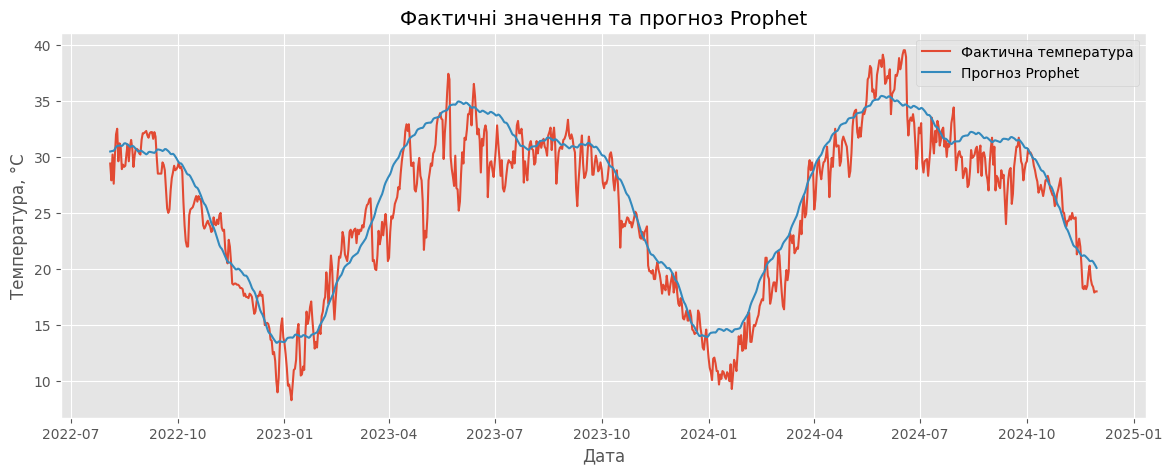

In [23]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 5))
plt.plot(prophet_test["ds"], y_true_prophet, label="Фактична температура")
plt.plot(prophet_test["ds"], y_pred_prophet, label="Прогноз Prophet")
plt.title("Фактичні значення та прогноз Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.legend()
plt.grid(True)
plt.show()


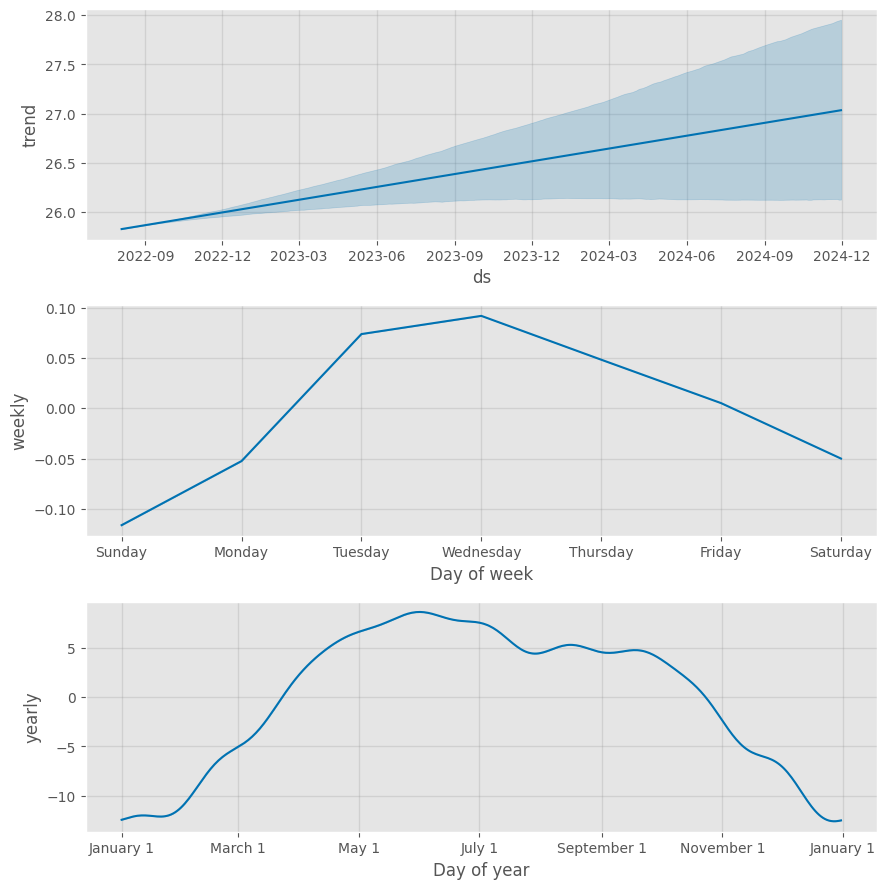

In [24]:
# Побудуйте компоненти моделі Prophet
model_prophet.plot_components(forecast_prophet)
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM

from sklearn.preprocessing import MinMaxScaler

#Масштабування температури
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(ts.values.reshape(-1, 1))

#Формування послідовностей за попередніми 30 днями
sequence_length = 30

X = []
y = []

for i in range(sequence_length, len(scaled_values)):
    X.append(scaled_values[i-sequence_length:i, 0])
    y.append(scaled_values[i, 0])

X = np.array(X)
y = np.array(y)

X = X.reshape(X.shape[0], X.shape[1], 1)

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)


Розмір X: (4219, 30, 1)
Розмір y: (4219,)


In [26]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
lstm_split = split_point - sequence_length

X_train_lstm = X[:lstm_split]
X_test_lstm = X[lstm_split:]

y_train_lstm = y[:lstm_split]
y_test_lstm = y[lstm_split:]

print("X_train:", X_train_lstm.shape)
print("X_test:", X_test_lstm.shape)


X_train: (3369, 30, 1)
X_test: (850, 30, 1)


In [27]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Створення LSTM-моделі
model_lstm = Sequential([
    LSTM(50, return_sequences=True,
         input_shape=(sequence_length, 1)),
    Dropout(0.2),
    LSTM(50),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model_lstm.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# Навчіть LSTM-модель
history = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Epoch 1/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0350 - val_loss: 0.0061
Epoch 2/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0065 - val_loss: 0.0054
Epoch 3/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0060 - val_loss: 0.0050
Epoch 4/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0055 - val_loss: 0.0049
Epoch 5/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0052 - val_loss: 0.0047
Epoch 6/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0048 - val_loss: 0.0044
Epoch 7/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0046 - val_loss: 0.0040
Epoch 8/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0043 - val_loss: 0.0039
Epoch 9/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0041 - val_loss: 0.0037
Epoch 10/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0041 - val_loss: 0.0035
Epoch 11/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0038 - val_loss: 0.0034
Epoch 12/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0037 - val_l

In [29]:
# Виведіть структуру LSTM-моделі
model_lstm.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,955 (359.20 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,304 (239.47 KB)

In [30]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування

#Прогноз LSTM
predictions_scaled = model_lstm.predict(X_test_lstm)

#Повернення до початкової шкали температури
forecast_lstm = scaler.inverse_transform(predictions_scaled).flatten()
actual_lstm = scaler.inverse_transform(
    y_test_lstm.reshape(-1, 1)
).flatten()

#Дати для прогнозу
dates_lstm = ts.index[split_point:]

print("Кількість фактичних значень:", len(actual_lstm))
print("Кількість прогнозів:", len(forecast_lstm))
print("Кількість дат:", len(dates_lstm))


27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Кількість фактичних значень: 850
Кількість прогнозів: 850
Кількість дат: 850


In [31]:
#Сформуйте часові мітки для тестового прогнозу LSTM
dates_lstm = ts.index[split_point:]

print("Початок тестового періоду:", dates_lstm[0])
print("Кінець тестового періоду:", dates_lstm[-1])
print("Кількість дат:", len(dates_lstm))


Початок тестового періоду: 2022-08-04 00:00:00
Кінець тестового періоду: 2024-11-30 00:00:00
Кількість дат: 850


In [32]:
# Обчисліть MAE, RMSE, MAPE для LSTM
mae_lstm = mean_absolute_error(actual_lstm, forecast_lstm)

rmse_lstm = np.sqrt(
    mean_squared_error(actual_lstm, forecast_lstm)
)

mape_lstm = calculate_mape(actual_lstm, forecast_lstm)

print("Результати LSTM:")
print("MAE:", round(mae_lstm, 3))
print("RMSE:", round(rmse_lstm, 3))
print("MAPE:", round(mape_lstm, 3), "%")

Результати LSTM:
MAE: 1.143
RMSE: 1.495
MAPE: 5.068 %


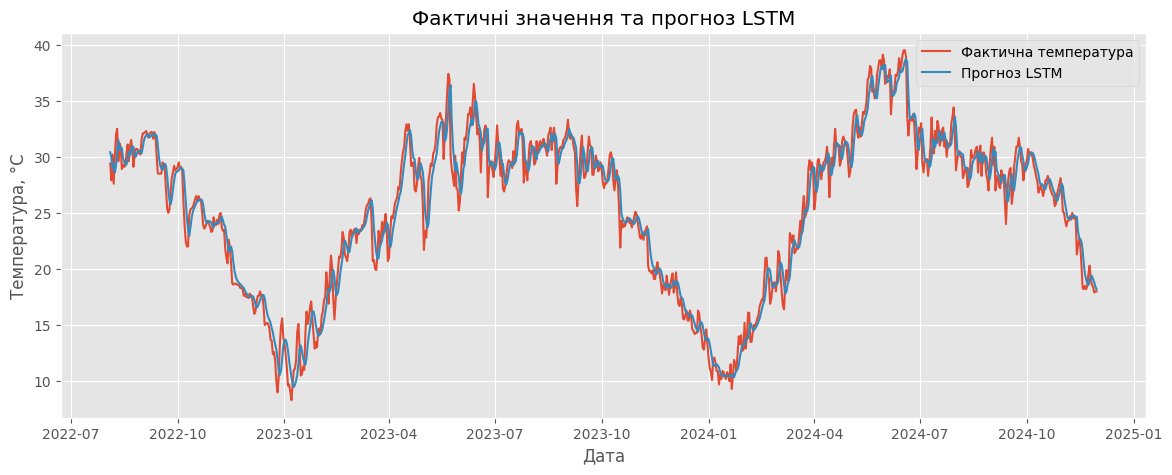

In [33]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 5))

plt.plot(dates_lstm, actual_lstm, label="Фактична температура")
plt.plot(dates_lstm, forecast_lstm, label="Прогноз LSTM")

plt.title("Фактичні значення та прогноз LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

In [34]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results = pd.DataFrame({
    "Модель": ["ARIMA", "Prophet", "LSTM"],
    "MAE": [mae_arima, mae_prophet, mae_lstm],
    "RMSE": [rmse_arima, rmse_prophet, rmse_lstm],
    "MAPE (%)": [mape_arima, mape_prophet, mape_lstm]
})

display(results.round(3))

best_mae = results.loc[results["MAE"].idxmin(), "Модель"]
best_rmse = results.loc[results["RMSE"].idxmin(), "Модель"]
best_mape = results.loc[results["MAPE (%)"].idxmin(), "Модель"]

print("Найкраща модель за MAE:", best_mae)
print("Найкраща модель за RMSE:", best_rmse)
print("Найкраща модель за MAPE:", best_mape)


,Модель,MAE,RMSE,MAPE (%)
0,ARIMA,6.196,8.404,35.793
1,Prophet,2.067,2.646,9.342
2,LSTM,1.143,1.495,5.068


Найкраща модель за MAE: LSTM
Найкраща модель за RMSE: LSTM
Найкраща модель за MAPE: LSTM


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


## Висновок

Під час виконання лабораторної роботи я проаналізувала дані про температуру в Делі та побудувала три моделі прогнозування: ARIMA, Prophet і LSTM. Для порівняння моделей я використала метрики MAE, RMSE і MAPE. За результатами аналізу найкращою виявилася модель LSTM, оскільки вона показала найменші похибки за всіма трьома метриками. Отже, у цій роботі модель LSTM продемонструвала найкращу якість прогнозування температури.